# PT-04 — Regressão logística para concessão de crédito

**Valentim Soares de Andrade Neto — 2019027210**

Fonte: `Exercicio_Regressao_Logistica.pdf`, nesta pasta. O exercício fornece um
modelo já treinado: aplicamos seus coeficientes, sem treinar um novo modelo.
Todos os valores são fictícios e as interpretações se referem a esse modelo.

\[
z=-4.5+0.08\,Idade-0.00003\,Renda+1.2\,Atrasos+0.9\,Divida,
\qquad p=\frac{1}{1+e^{-z}}.
\]

Idade em anos; renda **anual em reais**; atrasos no último ano; dívida baixa = 0
e alta = 1. O evento positivo, $Y=1$, é **inadimplência**.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option('display.precision', 6)

def sigmoide(z):
    # logaddexp evita overflow, inclusive para logits extremos.
    z = np.asarray(z, dtype=float)
    return np.exp(-np.logaddexp(0, -z))

def calcular_logit(idade, renda, atrasos, divida):
    return (-4.5 + 0.08 * np.asarray(idade)
            - 0.00003 * np.asarray(renda)
            + 1.2 * np.asarray(atrasos) + 0.9 * np.asarray(divida))

def classificar(probabilidades, limiar=0.5):
    if not 0 <= limiar <= 1:
        raise ValueError('O limiar deve estar entre 0 e 1.')
    p = np.asarray(probabilidades, dtype=float)
    if not np.all(np.isfinite(p) & (p >= 0) & (p <= 1)):
        raise ValueError('As probabilidades devem ser finitas e estar entre 0 e 1.')
    return (p >= limiar).astype(int)


## Parte 1 — Implementação (20%)

Calculamos separadamente as contribuições para o logit e aplicamos a sigmoide.
Por exemplo, para A: $z=-4.5+0.08(25)-0.00003(40000)=-3.7$.


In [2]:
clientes = pd.DataFrame({
    'Cliente': list('ABCD'), 'Idade': [25, 40, 55, 30],
    'Renda': [40000, 50000, 120000, 80000],
    'Atrasos': [0, 2, 1, 3], 'Divida': [0, 1, 0, 1],
}).set_index('Cliente')
contribuicoes = pd.DataFrame({
    'Intercepto': -4.5, 'Idade': 0.08 * clientes.Idade,
    'Renda': -0.00003 * clientes.Renda, 'Atrasos': 1.2 * clientes.Atrasos,
    'Divida': 0.9 * clientes.Divida,
})
clientes['Logit'] = calcular_logit(clientes.Idade, clientes.Renda,
                                   clientes.Atrasos, clientes.Divida)
clientes['Probabilidade'] = sigmoide(clientes.Logit)
clientes['Probabilidade (%)'] = 100 * clientes.Probabilidade
display(contribuicoes)
display(clientes)


,Intercepto,Idade,Renda,Atrasos,Divida
Cliente,,,,,
A,-4.5,2.0,-1.2,0.0,0.0
B,-4.5,3.2,-1.5,2.4,0.9
C,-4.5,4.4,-3.6,1.2,0.0
D,-4.5,2.4,-2.4,3.6,0.9


,Idade,Renda,Atrasos,Divida,Logit,Probabilidade,Probabilidade (%)
Cliente,,,,,,,
A,25,40000,0,0,-3.700000e+00,0.024127,2.412702
B,40,50000,2,1,5.000000e-01,0.622459,62.245933
C,55,120000,1,0,-2.500000e+00,0.075858,7.585818
D,30,80000,3,1,-3.330669e-16,0.500000,50.000000


## Parte 2 — Interpretação dos coeficientes (25%)

**a)** Por aumento de **uma unidade**, Atrasos tem o maior coeficiente positivo
($1.2$), seguido por Divida ($0.9$) e Idade ($0.08$). Um atraso adicional
acrescenta mais ao logit que um ano adicional ou a passagem de dívida baixa para
alta. Isso **não estabelece importância global**: as unidades, amplitudes e
distribuições das variáveis são diferentes. Por exemplo, 15 anos acrescentam
$1.2$ ao logit, o mesmo que um atraso.

**b)** Mantidas as demais variáveis constantes, maior renda reduz o logit e a
probabilidade prevista. Isso é compatível com maior capacidade de pagamento,
mas o sinal do coeficiente expressa uma associação do modelo, sem provar
causalidade. Um aumento de R$ 10.000 anuais reduz o logit em $0.3$.

**c)** Um atraso adicional aumenta o logit (logaritmo das chances) em **1.2**,
mantidas as demais variáveis. Não aumenta a probabilidade em 1.2 nem em 120
pontos percentuais: o efeito na probabilidade depende do ponto inicial.

**d)** As chances são $p/(1-p)$ e a razão de chances por unidade é $e^\beta$.
Para Atrasos, $e^{1.2}\approx3.3201$: um atraso multiplica as chances por 3.32
(aumento de aproximadamente 232%). Para Divida, $e^{0.9}\approx2.4596$:
passar de baixa para alta multiplica as chances por 2.46 (aumento de 146%).
São multiplicadores das **chances**, não das probabilidades.


In [3]:
odds_ratios = pd.DataFrame({
    'Variável': ['Atrasos (+1)', 'Divida (0 → 1)'],
    'Coeficiente': [1.2, 0.9],
})
odds_ratios['Razão de chances'] = np.exp(odds_ratios.Coeficiente)
odds_ratios['Aumento das chances (%)'] = 100 * (odds_ratios['Razão de chances'] - 1)
display(odds_ratios)


,Variável,Coeficiente,Razão de chances,Aumento das chances (%)
0,Atrasos (+1),1.2,3.320117,232.011692
1,Divida (0 → 1),0.9,2.459603,145.960311


## Parte 3 — Efeito do limiar de decisão (25%)

**a–b)** Usamos os clientes **E–I**, cujas probabilidades são fornecidas na última
tabela do PDF. Classificamos como inadimplente quando $p \geq t$; caso contrário,
como adimplente. A igualdade pertence à classe positiva.


,Probabilidade,Limiar 0.5,Limiar 0.7
Cliente,,,
E,0.15,0,0
F,0.42,0,0
G,0.58,1,0
H,0.72,1,1
I,0.89,1,1


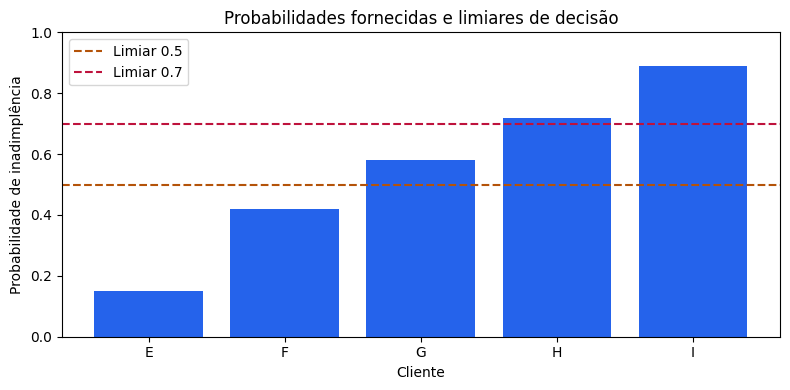

In [4]:
decisoes = pd.DataFrame({'Cliente': list('EFGHI'),
                         'Probabilidade': [0.15, 0.42, 0.58, 0.72, 0.89]}).set_index('Cliente')
for limiar in (0.5, 0.7):
    decisoes[f'Limiar {limiar}'] = classificar(decisoes.Probabilidade, limiar)
display(decisoes)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(decisoes.index, decisoes.Probabilidade, color='#2563eb')
for limiar, cor in [(0.5, '#b45309'), (0.7, '#be123c')]:
    ax.axhline(limiar, color=cor, linestyle='--', label=f'Limiar {limiar}')
ax.set(ylim=(0, 1), ylabel='Probabilidade de inadimplência', xlabel='Cliente',
       title='Probabilidades fornecidas e limiares de decisão')
ax.legend()
fig.tight_layout()
plt.show()


**c) Banco:** entre 0.5 e 0.7, escolheria **0.5**, sob a hipótese de que
conceder crédito a um inadimplente tem custo maior que perder um bom cliente.
O limiar menor sinaliza mais clientes como risco, reduzindo falsos negativos
(inadimplentes classificados como adimplentes), embora possa aumentar falsos
positivos (adimplentes classificados como inadimplentes).

**d) Marketing:** escolheria **0.7** para uma campanha cujo objetivo seja ampliar
o público e que tenha uma análise de crédito posterior, assumindo que a receita
esperada e o custo de perder bons clientes justifiquem maior tolerância a risco.
G passa a ser elegível; H e I continuam sinalizados como inadimplentes. Se
pré-aprovado significar concessão efetiva sem nova análise, essa escolha não é
automaticamente adequada: sob a hipótese conservadora do item c, manteria 0.5.

A escolha econômica não é determinada apenas pelo setor. Depende do valor da
operação, margem, perda em caso de inadimplência e custos de oportunidade.
Em um modelo simplificado de custos de classificação, com custos zero para
acertos, probabilidades calibradas e custos constantes, o limiar ótimo é
$t=C_{FP}/(C_{FP}+C_{FN})$. Sem custos e resultados reais, não se pode demonstrar
que um dos limiares maximiza o lucro. Não há rótulos reais no exercício para
calcular precisão, revocação ou matriz de confusão.


## Parte 4 — Análise crítica (30%)

**Afirmação 1:** 58% representa uma estimativa de probabilidade, não certeza.
O resultado individual de G continua desconhecido. Se o modelo estiver bem
calibrado, em muitos casos semelhantes com previsão de 58%, espera-se observar
aproximadamente 58% de inadimplência. Classificar G como 1 não elimina a incerteza.

**Afirmação 2:** o efeito positivo da idade vale **mantendo renda, atrasos e dívida
constantes**. Duas pessoas de idades diferentes podem ter outras características
que compensam esse efeito. No próprio exercício, C tem 55 anos e risco menor
que B, de 40 anos. A associação também não demonstra causalidade nem validade
fora da população em que o modelo foi estimado.

**Afirmação 3:** mudar o limiar altera as decisões, não os coeficientes nem as
probabilidades do modelo. Ao elevar o limiar, o conjunto de positivos previstos
diminui: falsos positivos não aumentam, falsos negativos não diminuem e a
revocação não aumenta (quando há positivos reais). A precisão pode aumentar,
mas isso não é garantido em uma amostra finita; depende dos rótulos dos casos
que deixam de ser classificados como positivos.

Com limiar 0.9, nenhum dos clientes E–I é positivo. Logo, não há falsos positivos
nesse grupo, mas qualquer inadimplente real seria falso negativo. A precisão
$TP/(TP+FP)$ fica indefinida porque não há previsões positivas; se houver
positivos reais, a revocação é zero, e, se não houver, também fica indefinida.
Sem os rótulos não podemos atribuir valores a TP, FP, FN e TN. Um limiar de 0.9
não torna o modelo automaticamente melhor.


In [5]:
display(decisoes[['Probabilidade']].assign(Limiar_09=classificar(decisoes.Probabilidade, 0.9)))


,Probabilidade,Limiar_09
Cliente,,
E,0.15,0
F,0.42,0
G,0.58,0
H,0.72,0
I,0.89,0


## Bônus — Inclinação e sensibilidade (+10%)

**1.** $z=-1.2+5X$ produz a transição mais íngreme. Como
$dp/dX=\beta p(1-p)$, a inclinação máxima é $\beta/4$: **1.25** para
$\beta=5$ e **0.125** para $\beta=0.5$. Os centros são, respectivamente,
$X=0.24$ e $X=2.4$.

**2.** O modelo com coeficiente 5 é mais sensível **na região da sua transição**.
Não necessariamente em todo X: longe dessa região a sigmoide satura perto de
0 ou 1, e a derivada fica pequena. No mesmo X, o modelo com coeficiente 0.5
pode ter maior derivada se o outro já estiver saturado.

**3.** Coeficientes muito grandes podem amplificar ruído de medição perto da
fronteira, produzir previsões extremas e indicar sobreajuste ou separação
completa/quase completa no treinamento. A sigmoide ingênua também pode sofrer
overflow. A escala de X deve ser considerada antes de avaliar a magnitude do
coeficiente; padronização, regularização e validação ajudam a investigar o caso.


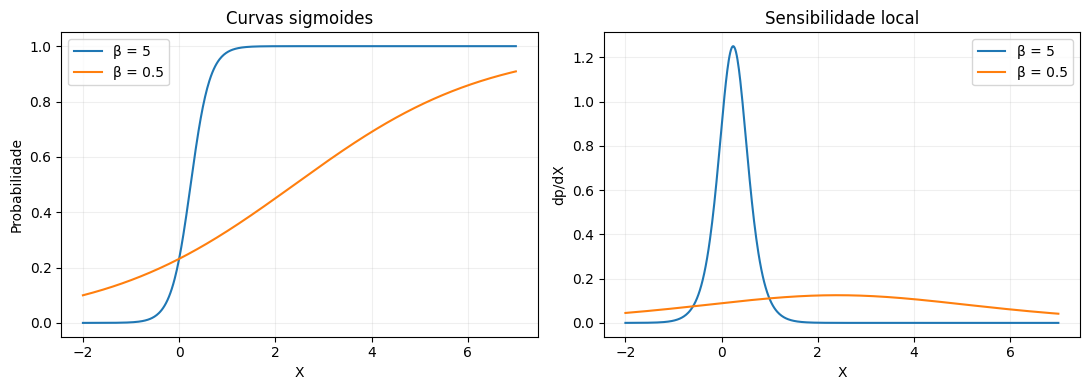

In [6]:
x = np.linspace(-2, 7, 600)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for beta in (5, 0.5):
    p = sigmoide(-1.2 + beta * x)
    axes[0].plot(x, p, label=f'β = {beta}')
    axes[1].plot(x, beta * p * (1-p), label=f'β = {beta}')
for ax, titulo, ylabel in zip(axes, ['Curvas sigmoides', 'Sensibilidade local'],
                            ['Probabilidade', 'dp/dX']):
    ax.set(title=titulo, xlabel='X', ylabel=ylabel)
    ax.grid(alpha=0.2)
    ax.legend()
fig.tight_layout()
plt.show()


## Verificação dos cálculos

Conferência com valores calculados por substituição, limites da sigmoide e decisões esperadas.

In [7]:
np.testing.assert_allclose(clientes.Logit, [-3.7, 0.5, -2.5, 0.0], atol=1e-12)
np.testing.assert_allclose(clientes.Probabilidade,
                           [0.0241270214, 0.6224593312, 0.0758581800, 0.5], atol=1e-10)
np.testing.assert_allclose(contribuicoes.sum(axis=1), clientes.Logit, atol=1e-12)
np.testing.assert_array_equal(classificar(decisoes.Probabilidade, 0.5), [0, 0, 1, 1, 1])
np.testing.assert_array_equal(classificar(decisoes.Probabilidade, 0.7), [0, 0, 0, 1, 1])
np.testing.assert_array_equal(classificar([0.5, 0.7], 0.5), [1, 1])
np.testing.assert_allclose(sigmoide([-1000, 0, 1000]), [0, 0.5, 1])
print('Todas as verificações passaram.')


Todas as verificações passaram.
